In [49]:
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

pd.df=pd.read_csv('/content/drive/MyDrive/ML/iris.csv')
x=iris.data
pd.df.head(11)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,sepal length in cm,sepal width in cm,petal length in cm,petal width in cm,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
5,5.4,3.9,1.7,0.4,Iris-setosa
6,4.6,3.4,1.4,0.3,Iris-setosa
7,5.0,3.4,1.5,0.2,Iris-setosa
8,4.4,2.9,1.4,0.2,Iris-setosa
9,4.9,3.1,1.5,0.1,Iris-setosa


In [38]:
# 2. Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [39]:
# 3. Find the optimal K using the Elbow Method
inertia = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)
    print(inertia)

[600.0]
[600.0, 222.36170496502302]
[600.0, 222.36170496502302, 139.82049635974974]
[600.0, 222.36170496502302, 139.82049635974974, 114.09254690403094]
[600.0, 222.36170496502302, 139.82049635974974, 114.09254690403094, 90.92751382392049]
[600.0, 222.36170496502302, 139.82049635974974, 114.09254690403094, 90.92751382392049, 81.54439095511782]
[600.0, 222.36170496502302, 139.82049635974974, 114.09254690403094, 90.92751382392049, 81.54439095511782, 72.6311438266719]
[600.0, 222.36170496502302, 139.82049635974974, 114.09254690403094, 90.92751382392049, 81.54439095511782, 72.6311438266719, 62.540605695781245]
[600.0, 222.36170496502302, 139.82049635974974, 114.09254690403094, 90.92751382392049, 81.54439095511782, 72.6311438266719, 62.540605695781245, 55.119492805290584]
[600.0, 222.36170496502302, 139.82049635974974, 114.09254690403094, 90.92751382392049, 81.54439095511782, 72.6311438266719, 62.540605695781245, 55.119492805290584, 47.39103517634709]


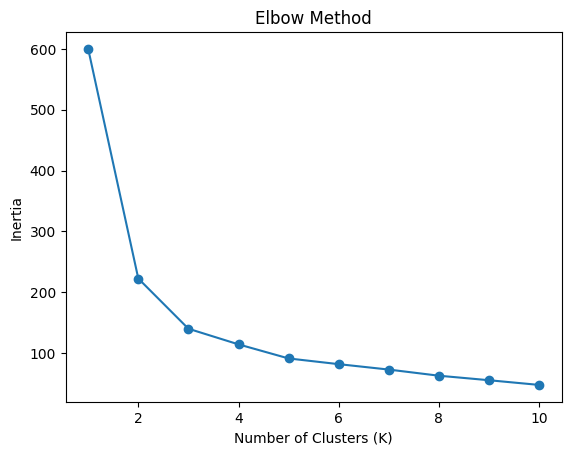

In [40]:
#elbow methode Graph
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [41]:
# 4. Perform K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

print("Cluster Labels:")
print(labels)

print("Cluster Centroids:")
print(kmeans.cluster_centers_)


Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
Cluster Centroids:
[[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]


In [42]:
# 5. Reduce data to 2 dimensions using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

centroids_pca = pca.transform(kmeans.cluster_centers_)

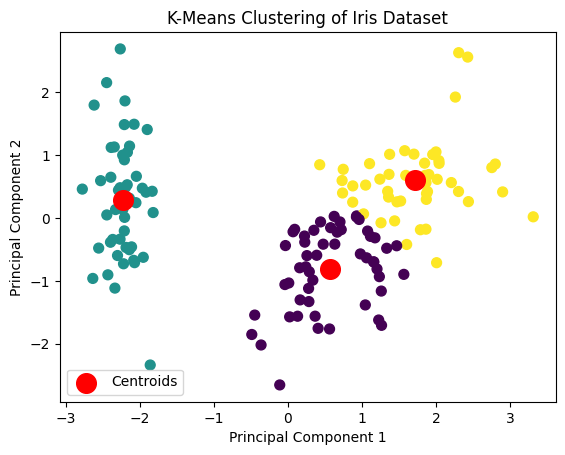

In [48]:
# 6. Visualize the clusters
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels, cmap='viridis', s=50
)

plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    marker='o', s=200, color='red',
    label='Centroids'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of Iris Dataset")
plt.legend()
plt.show()